# Spatial Weights and Spatial Lags

Companion notebook for [spatial_weights.md](../../notes/spatial_statistics/spatial_weights.md). We build rook/queen, distance-band, $k$-NN and inverse-distance weights, row-standardize them, compute spatial lags, and audit islands, symmetry and sensitivity.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
np.set_printoptions(precision=3, suppress=True)


## 1. Rook and queen contiguity on a grid

Contiguity matrices for a rectangular grid, built from cell offsets. On the $2\times2$ grid, rook gives 2 neighbors per cell and queen gives 3.

In [2]:
def grid_weights(nr, nc, queen=False):
    n = nr*nc; W = np.zeros((n, n))
    for r in range(nr):
        for c in range(nc):
            for dr in (-1,0,1):
                for dc in (-1,0,1):
                    if (dr, dc) == (0, 0): continue
                    if not queen and dr != 0 and dc != 0: continue
                    rr, cc = r+dr, c+dc
                    if 0 <= rr < nr and 0 <= cc < nc:
                        W[r*nc+c, rr*nc+cc] = 1
    return W

W_rook, W_queen = grid_weights(2,2), grid_weights(2,2,queen=True)
print(W_rook); print(W_queen)
x = np.array([10,14,8,20.])
print("rook sum lag:", W_rook@x)

[[0. 1. 1. 0.]
 [1. 0. 0. 1.]
 [1. 0. 0. 1.]
 [0. 1. 1. 0.]]
[[0. 1. 1. 1.]
 [1. 0. 1. 1.]
 [1. 1. 0. 1.]
 [1. 1. 1. 0.]]
rook sum lag: [22. 30. 30. 22.]


## 2. Row standardization and the spatial lag

Dividing each row by its sum turns the neighbor sum into a neighbor average. We also center the data, giving the $Wz$ used in the Moran scatterplot. Expected: lag $(11,15,15,11)$ and $Wz=(-2,2,2,-2)$.

In [3]:
def row_standardize(W):
    s = W.sum(1, keepdims=True)
    return np.divide(W, s, out=np.zeros_like(W), where=s > 0)

Wr = row_standardize(W_rook)
z = x - x.mean()
print("row sums:", Wr.sum(1))
print("lag Wx :", Wr@x)
print("z      :", z)
print("lag Wz :", Wr@z)
print("Moran's I = %.3f" % (len(x)/Wr.sum() * z@Wr@z/(z@z)))

row sums: [1. 1. 1. 1.]
lag Wx : [11. 15. 15. 11.]
z      : [-3.  1. -5.  7.]
lag Wz : [-2.  2.  2. -2.]
Moran's I = -0.190


## 3. Distance-band weights, thresholds and islands

Points on a line at $0,1,3,7$ km. A threshold of 2.5 km isolates the last point; 4.5 km links everything reachable.

In [4]:
p = np.array([0,1,3,7.])
D = np.abs(p[:,None]-p[None])
def band(D, d0): return ((D > 0) & (D <= d0)).astype(float)

for d0 in (2.5, 4.5):
    W = band(D, d0)
    print(f"d0={d0}: degrees={W.sum(1)}, islands at index {np.where(W.sum(1)==0)[0]}")
print(band(D, 2.5))

d0=2.5: degrees=[1. 2. 1. 0.], islands at index [3]
d0=4.5: degrees=[2. 2. 3. 1.], islands at index []
[[0. 1. 0. 0.]
 [1. 0. 1. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 0.]]


## 4. $k$-NN weights are asymmetric

Points at $0,1,10$ with $k=1$: C selects B, but B selects A. The union and mutual rules give different symmetric graphs.

In [5]:
def knn(coords, k):
    coords = np.asarray(coords, float).reshape(len(coords), -1)
    Dm = np.linalg.norm(coords[:,None]-coords[None], axis=2)
    np.fill_diagonal(Dm, np.inf)
    W = np.zeros_like(Dm)
    for i in range(len(coords)):
        W[i, np.argsort(Dm[i])[:k]] = 1
    return W

Wk = knn([0,1,10], 1)
print(Wk)
print("symmetric?", np.array_equal(Wk, Wk.T))
print("union:\n", np.maximum(Wk, Wk.T))
print("mutual:\n", np.minimum(Wk, Wk.T))

[[0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]]
symmetric? False
union:
 [[0. 1. 0.]
 [1. 0. 1.]
 [0. 1. 0.]]
mutual:
 [[0. 1. 0.]
 [1. 0. 0.]
 [0. 0. 0.]]


## 5. Inverse-distance weights and row standardization breaking symmetry

Inverse-distance weights $d^{-\alpha}$: with distances 1 and 2 and $\alpha=1$ the standardized weights are $2/3,1/3$. Also, a symmetric binary star graph becomes asymmetric once rows are standardized.

In [6]:
d = np.array([1., 2.])
for alpha in (1, 2):
    w = d**-alpha
    print(f"alpha={alpha}: raw={w}, standardized={w/w.sum()}")
print("lag with x_B=12, x_C=6:", (d**-1/(d**-1).sum()) @ np.array([12, 6.]))

star = np.zeros((4,4)); star[0,1:] = 1; star[1:,0] = 1   # hub with 3 leaves
Ws = row_standardize(star)
print("binary symmetric:", np.allclose(star, star.T), "| standardized symmetric:", np.allclose(Ws, Ws.T))
print(Ws)

alpha=1: raw=[1.  0.5], standardized=[0.667 0.333]
alpha=2: raw=[1.   0.25], standardized=[0.8 0.2]
lag with x_B=12, x_C=6: 10.0
binary symmetric: True | standardized symmetric: False
[[0.    0.333 0.333 0.333]
 [1.    0.    0.    0.   ]
 [1.    0.    0.    0.   ]
 [1.    0.    0.    0.   ]]


## 6. Sensitivity of the lag to the weights definition

For random points we compare the lag of one variable under distance band, $k=4$ and $k=8$ weights. Both the lag values and Moran's $I$ change.

band 1.5 : islands= 3  mean degree=4.1  Moran I=0.654
kNN 4    : islands= 0  mean degree=4.0  Moran I=0.659
kNN 8    : islands= 0  mean degree=8.0  Moran I=0.662


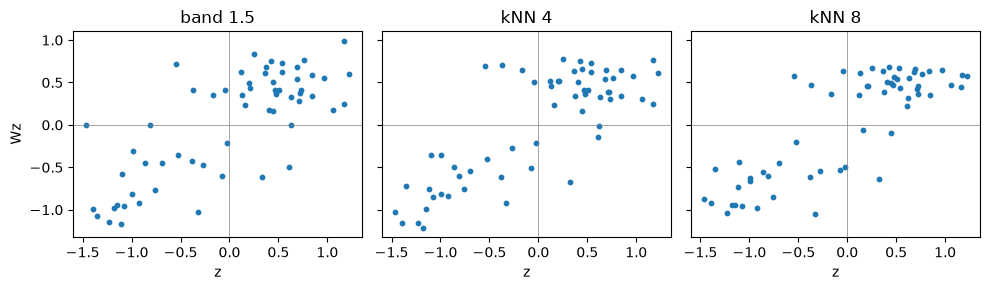

In [7]:
n = 60
pts = rng.uniform(0, 10, (n, 2))
val = np.sin(pts[:,0]/2) + 0.3*rng.normal(size=n)       # smooth trend + noise
Dm = np.linalg.norm(pts[:,None]-pts[None], axis=2)
Ws_ = {"band 1.5": row_standardize(band(Dm, 1.5)),
       "kNN 4": row_standardize(knn(pts, 4)),
       "kNN 8": row_standardize(knn(pts, 8))}
zc = val - val.mean()
lags = {}
for name, Wm in Ws_.items():
    lags[name] = Wm @ zc
    I = n/Wm.sum() * zc@Wm@zc/(zc@zc)
    print(f"{name:9s}: islands={(Wm.sum(1)==0).sum():2d}  mean degree={(Wm>0).sum(1).mean():.1f}  Moran I={I:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(10,3), sharey=True)
for a, (name, l) in zip(ax, lags.items()):
    a.scatter(zc, l, s=10); a.axhline(0, c="gray", lw=.5); a.axvline(0, c="gray", lw=.5)
    a.set_title(name); a.set_xlabel("z")
ax[0].set_ylabel("Wz"); plt.tight_layout(); plt.show()

## Takeaways

- $W$ is part of the model: rook, queen, band and $k$-NN encode different notions of neighbor.
- Row standardization turns sums into averages but destroys numerical symmetry.
- Distance bands can create islands; $k$-NN cannot, but is directed.
- Always report how $W$ was constructed and check results against plausible alternatives.